# Assignment 2 – Neural Networks
## Voice commands for SLIFTS elevators with a deep neural network

**Course:** ZM002 Artificial Intelligence – Zuyd University of Applied Sciences
**Student:** Caio Alcantara

This notebook contains the three deliverables of the assignment in one place:

| Deliverable | Sections |
|---|---|
| **Advisory report** – problem analysis, research on preprocessing and architectures, proposal with alternatives, final advice | 1, 2, 8 |
| **Realisation** – implementation of the DNN, explained with in-code comments | 3, 4, 5, 7 |
| **Evaluation report** – performance metrics, interpreted and discussed | 6 |

## 1. Introduction

### 1.1 The problem

After the COVID pandemic, the elevator company SLIFTS (Smart Lifts in Floor Transition Systems) has seen
fewer passengers in its elevators, because people do not want to touch the buttons. SLIFTS therefore
wants elevators that can be controlled by **spoken commands**: the passenger says a word such as
*"up"* or *"stop"* and the elevator reacts, without anyone touching a button.

SLIFTS asked for advice on two questions: **how should the audio be pre-processed**, and **which
neural network architecture is suitable** for recognising a fixed number of spoken commands? The
advice must be backed by a working proof of concept and an evaluation of its performance.

### 1.2 Problem analysis

Recognising a small, fixed set of spoken words is known as **keyword spotting** (or speech command
recognition). It is a much simpler task than full speech recognition: the system does not need to
understand sentences, it only has to decide which of a few known words was spoken. In machine learning
terms this is **supervised multi-class classification**: the input is a short audio clip and the output
is one of the known commands.

The elevator context adds a few requirements to the solution:

| Requirement | Why it matters in an elevator |
|---|---|
| **Speaker independence** | Every passenger is a new voice (age, gender, accent). The system must work for people it never heard before. |
| **Robustness to noise** | Other passengers talk, the doors and the motor make noise. |
| **Small and fast model** | The model should run on a small computer inside the elevator and react within a fraction of a second. |
| **Few wrong actions** | Reacting to the wrong command (e.g. going *down* when the passenger said *up*) is worse than not reacting at all, since the passenger can simply repeat the command. |

This proof of concept focuses on the first, third and fourth requirement: the network is evaluated on
speakers it has never seen, model size is taken into account when comparing architectures, and the
elevator only acts on confident predictions (section 7).
Robustness to real elevator noise needs real recordings and is left as future work (section 8).

### 1.3 The mini speech commands dataset as a stand-in

As real elevator recordings are not available, the *mini speech commands* dataset is used. It is a
small excerpt of Google's Speech Commands dataset (Warden, 2018) and contains **8 words**:
`down`, `go`, `left`, `no`, `right`, `stop`, `up` and `yes`, with 1000 one-second recordings
(16 kHz, mono) per word from many different speakers.

Several of these words map naturally to elevator commands: **up** and **down** select the direction,
**stop** and **go** stop or start the elevator, and **yes**/**no** can be used to confirm an action.
`left` and `right` are not useful in an elevator, but are kept as extra classes, because more
classes make the task harder and the evaluation more realistic. A real product would need other words
too (floor numbers, *open*, *close*), but the approach stays the same: only the training data changes.

## 2. Theoretical background

A speech command recogniser turns a sound wave into one of a few class labels. This happens in two
steps, and SLIFTS asked advice about both of them:

1. **Preprocessing** (feature extraction): the raw recording is converted into a representation that
   makes the important information easy to see for a neural network (section 2.2).
2. **Classification**: a neural network maps this representation to a probability for every command
   (section 2.3).

The research in this section is based mainly on two papers from Google. Warden (2018) describes the
Speech Commands dataset, of which our dataset is an excerpt, and how models on it should be
evaluated. Sainath & Parada (2015) compare neural network architectures for *small-footprint keyword
spotting*, i.e. recognising a few words with a model small enough to run on a device, which is
exactly the situation of an elevator. The implementation follows the TensorFlow tutorial *Simple audio
recognition* (TensorFlow, n.d.), which uses the same mini speech commands dataset.

### 2.1 Audio as data

A microphone measures air pressure many times per second. Every recording in the dataset is sampled at
**16 kHz**, so one second of audio is a list of **16 000 numbers** (amplitudes between -1 and 1). This
list is called the **waveform**.

The waveform can in principle be fed directly into a neural network, but it is hard to learn from:

- it is long: 16 000 inputs for a single word;
- the same word looks completely different as a waveform when it is spoken a little earlier, louder,
  faster or by another voice;
- the information that distinguishes words, *which frequencies are present and how they change over
  time*, is not directly visible in the amplitudes.

That is why speech is almost always converted into a **time-frequency representation** first.

### 2.2 Preprocessing options

**Step 1: equal length.** A neural network needs inputs of a fixed size, but some clips in the dataset
are shorter than one second (Warden, 2018, cut every recording to the loudest second, or less). All
clips are therefore **padded with zeros** to exactly 16 000 samples.

**Step 2: time-frequency representation.** The **Short-Time Fourier Transform (STFT)** cuts the
waveform into short overlapping windows (frames) and computes for every frame how strong each
frequency is. Placing the frames next to each other gives a **spectrogram**: a 2D "image" with time on
one axis, frequency on the other, and the energy as the brightness of each pixel. Different words
produce clearly different patterns in this image.

Two refinements bring the spectrogram closer to human hearing:

- **Mel scale.** Humans hear differences between low frequencies much better than between high
  frequencies. The Mel scale ($m = 2595 \log_{10}(1 + f/700)$) groups the frequencies into a small
  number of bands (filterbanks) that are narrow for low frequencies and wide for high frequencies.
  This reduces e.g. 257 frequency bins to 40 Mel bands, while keeping the information that matters
  for speech.
- **Logarithm.** Loudness is also perceived logarithmically. Taking the log of the energies compresses
  the very large range of values, so that quiet but important details are not dwarfed by loud ones.

The result is the **log-Mel spectrogram** (also called log-Mel filterbank features). A further step,
**MFCC**, applies a discrete cosine transform to the log-Mel features to decorrelate them into a few
coefficients; this was needed for older models (e.g. Gaussian mixture models), but CNNs work well on
the log-Mel features directly and can exploit the local structure that the DCT removes.

| Representation | How it works | Pros | Cons | Used by |
|---|---|---|---|---|
| **Raw waveform** | The 16 000 samples as they are | No information lost, no design choices | Long input; the network must learn the frequency analysis itself and needs much more data | – |
| **Spectrogram (STFT)** | Energy per frequency bin per frame | Simple, frequency content visible as an image | Many frequency bins (e.g. 129 or 257), high frequencies over-represented compared to hearing | TensorFlow tutorial (frames of 255 samples, step 128) |
| **Log-Mel spectrogram** | STFT, grouped into Mel bands, logarithm | Compact (e.g. 40 bands), matches human hearing, local time-frequency structure suited to a CNN | A few extra parameters to choose (number of bands, window size) | Sainath & Parada (2015): 40 bands, 25 ms windows, 10 ms step |
| **MFCC** | DCT of the log-Mel features, keep the first ~13 coefficients | Very compact | Removes the local frequency structure a CNN can use | Classic speech systems |

**Step 3: normalisation.** The values are scaled to zero mean and unit variance (statistics computed
on the training set only), which makes the training of the network faster and more stable.

**Data augmentation** (optional). Robustness to noise can be improved by adding background noise to
the training clips. Sainath & Parada (2015) trained on clips with car and cafeteria noise added at a
signal-to-noise ratio between -5 and +10 dB, and the full Speech Commands dataset contains background
noise recordings for this purpose (Warden, 2018). The mini dataset does not include these recordings,
so augmentation is not used in this proof of concept but recommended for the real system (section 8).

### 2.3 Neural network architectures

All architectures below end with a **softmax** layer with one output per command, which turns the
outputs of the network into probabilities that add up to 1. They differ in how they process the input.

**Fully connected network (DNN / MLP).** Every input value is connected to every neuron of the next
layer. Before 2015, Google's keyword spotter ("Ok Google") used such a network with 3 hidden layers of
128 ReLU units on top of log-Mel features (Sainath & Parada, 2015). Sainath & Parada point out two
weaknesses:

1. *A DNN ignores the topology of the input.* The inputs could be shuffled in any fixed order and the
   DNN would learn the same. But in a spectrogram, neighbouring values in time and frequency are
   strongly related, and that structure is thrown away.
2. *A DNN does not handle shifts well.* Different speakers and speaking styles shift the pattern of a
   word in frequency (and in time). A DNN can only learn to cope with this if it is very large and
   sees many examples.

**Convolutional neural network (CNN).** A CNN slides small filters (e.g. 3×3 values) over the
spectrogram. The same filter weights are used at every position (*weight sharing*), so a filter that
detects a certain pattern finds it wherever it occurs. After a convolution, **max-pooling** keeps only
the strongest response in small regions, which, according to Sainath & Parada, "removes variability in
the time-frequency space that exists due to speaking styles, channel distortions, etc." This answers
both weaknesses of the DNN with far fewer parameters. In their experiments, a CNN with two
convolutional layers (`cnn-trad-fpool3`) and the same number of parameters as the DNN (about 250K)
reduced the number of missed keywords by **more than 41%** relative to the DNN, in clean as well as
noisy conditions; pooling in time as well as in frequency improved it further (44%). This CNN became the
default model of TensorFlow's speech commands example, which reached **88.2%** accuracy on the full
12-class Speech Commands task (Warden, 2018).

**Other architectures** exist, but are not explored in this assignment:

| Architecture | Input | Pros | Cons |
|---|---|---|---|
| **DNN / MLP** | Flattened spectrogram | Simple, fast | Ignores time-frequency structure, sensitive to shifts, needs many parameters (Sainath & Parada, 2015) |
| **2D CNN** | Spectrogram as an image | Local patterns, robust to shifts, few parameters, well proven for keyword spotting (Sainath & Parada, 2015) | Fixed input length |
| **1D CNN** | Raw waveform | No preprocessing needed | Must learn the frequency analysis itself; needs more data and computation |
| **Recurrent network (LSTM/GRU)** | Spectrogram, frame by frame | Models the order of sounds, handles variable lengths | Slower to train, sequential computation; for one-second clips the order is also captured by a CNN |
| **Pre-trained model + transfer learning** | Waveform or spectrogram | Uses knowledge from very large datasets, good with little data | Large models, hard to run on a small device in the elevator |

The task of SLIFTS (short clips, a fixed number of words, a small device in the elevator) matches the
setting of Sainath & Parada exactly, so the **2D CNN on a spectrogram** is the most suitable
architecture. The DNN is used as a baseline to verify that the CNN is indeed better.

### 2.4 Training and evaluation

**Training.** The network is trained by minimising the **cross-entropy loss**: the lower the probability
the network gives to the correct command, the higher the loss. The weights are updated with the **Adam**
optimiser, a variant of gradient descent that adapts the step size for every weight. Training data is
passed through the network in mini-batches, and one pass over all training data is an *epoch*.

**Overfitting.** With 8000 clips, a network can easily memorise the training data instead of learning
general patterns. Three common measures are used against this:

- **Dropout**: during training, a random part of the neurons is switched off, so the network cannot
  rely on a few specific neurons;
- **Early stopping**: training stops when the loss on the validation set no longer improves;
- **A small model**: the CNN already needs far fewer parameters than a DNN.

**Data split by speaker.** The data is split into a training set (to learn the weights), a validation
set (to choose hyperparameters and stop training) and a test set (only used once, for the final
evaluation). In the Speech Commands dataset, the first part of every file name (before `_nohash_`) is
an anonymous speaker ID (Warden, 2018). The reference implementation of the dataset ignores everything
after `_nohash_` when assigning files to a set, so all recordings of one speaker end up in the same set.
This is important for SLIFTS: if the same voice were in both the training and test set, the test
accuracy could be too optimistic, while in the elevator every passenger is a new voice. Note that the
TensorFlow tutorial splits the files randomly, without looking at the speaker.

**Metrics.** Warden (2018) proposes the **top-one accuracy** as the standard metric: the fraction of
test clips for which the most probable command is the correct one. Because accuracy is a single number,
it is complemented with metrics per command:

| Metric | Meaning | Relevance for the elevator |
|---|---|---|
| **Accuracy** | Fraction of all test clips that are classified correctly | Overall quality, comparable to the literature |
| **Precision** (per command) | Of all clips predicted as e.g. *down*, the fraction that really was *down* | Low precision = the elevator performs an action nobody asked for |
| **Recall** (per command) | Of all clips that really were *down*, the fraction that was recognised | Low recall = the passenger has to repeat the command |
| **F1-score** | Harmonic mean of precision and recall | One number per command |
| **Confusion matrix** | For every true command, how often it was predicted as each command | Shows which words are confused (e.g. *go* and *no*) |
| **Number of parameters** | Size of the model | Must fit on a small device in the elevator |

Warden also notes that real products receive a continuous stream of audio instead of clean one-second
clips, which requires extra metrics (missed words, false alarms on background noise). This is outside
the scope of this proof of concept and is discussed in section 8.

### 2.5 Proposed solution and alternatives

| Component | Proposed choice | Alternative compared in section 6 | Based on |
|---|---|---|---|
| Input length | Zero-padding to 16 000 samples (1 s) | – | TensorFlow tutorial |
| Representation | **Log-Mel spectrogram**: 40 Mel bands, 25 ms windows, 10 ms step | Linear STFT spectrogram as in the TensorFlow tutorial | Sainath & Parada (2015) |
| Normalisation | Zero mean, unit variance, statistics of the training set | – | TensorFlow tutorial |
| Architecture | **2D CNN**: three convolution blocks with max-pooling in time and frequency, a dense layer and a softmax output; smaller than the DNN | DNN with 3 hidden layers of 128 ReLU units (baseline) | Sainath & Parada (2015), TensorFlow tutorial |
| Regularisation | Dropout and early stopping on the validation loss | – | TensorFlow tutorial |
| Training | Adam, cross-entropy loss | – | TensorFlow tutorial |
| Data split | 80 / 10 / 10 % **by speaker** | Random split as in the TensorFlow tutorial | Warden (2018) |
| Metrics | Accuracy, precision / recall / F1 per command, confusion matrix, number of parameters | – | Warden (2018) |

The evaluation in section 6 therefore answers three questions:

1. **Architecture:** is the CNN better than a DNN on this task, as Sainath & Parada found?
2. **Preprocessing:** does the log-Mel spectrogram give a better (or smaller) model than the plain
   STFT spectrogram used in the tutorial?
3. **Data split:** is the accuracy too optimistic when speakers are not separated between the
   training and test set?

## 3. Setup and the dataset

In [1]:
import pathlib
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from IPython.display import Audio, display

# Fix all random seeds so that the results in this notebook can be reproduced.
SEED = 42
keras.utils.set_random_seed(SEED)   # sets the seeds of Python, NumPy and TensorFlow

SAMPLE_RATE = 16000   # all clips are recorded at 16 kHz, so 1 second = 16000 samples

print('TensorFlow', tf.__version__, '| Keras', keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


The dataset is the *mini speech commands* excerpt from Kaggle
(https://www.kaggle.com/datasets/antfilatov/mini-speech-commands), which is the same archive that
TensorFlow publishes for its audio tutorial. If the folder is not present next to this notebook, the
cell below downloads it from the TensorFlow mirror (no Kaggle account needed).

In [2]:
DATA_DIR = pathlib.Path('mini_speech_commands')

if not DATA_DIR.exists():
    keras.utils.get_file(
        'mini_speech_commands.zip',
        origin='http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip',
        extract=True,
        cache_dir='.', cache_subdir='.')
    # Keras extracts into a folder named after the archive; move the data to DATA_DIR if needed
    extracted = pathlib.Path('mini_speech_commands_extracted') / 'mini_speech_commands'
    if extracted.exists():
        extracted.rename(DATA_DIR)

# Every sub-folder is one command (class); the README is not a class.
COMMANDS = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
print('commands:', COMMANDS)
for command in COMMANDS:
    print(f'{command:>6}: {len(list((DATA_DIR / command).glob("*.wav")))} clips')

commands: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
  down: 1000 clips
    go: 1000 clips
  left: 1000 clips
    no: 1000 clips
 right: 1000 clips
  stop: 1000 clips
    up: 1000 clips
   yes: 1000 clips


### 3.1 Exploring the data

Every clip gets two pieces of information from its location: the **label** is the name of the folder
(`up/...` is the command *up*), and the **speaker** is the first part of the file name, before
`_nohash_` (Warden, 2018). For example, `up/0ab3b47d_nohash_0.wav` is the first recording of the word
*up* by speaker `0ab3b47d`.

In [3]:
# All clips, sorted so that the order (and thus the split below) is always the same.
file_paths = np.array(sorted(str(p) for p in DATA_DIR.glob('*/*.wav')))

# label = position of the folder name in COMMANDS, e.g. 'down' -> 0, 'yes' -> 7
labels = np.array([COMMANDS.index(pathlib.Path(p).parent.name) for p in file_paths])

# speaker = the part of the file name before '_nohash_'
speakers = np.array([pathlib.Path(p).name.split('_nohash_')[0] for p in file_paths])

print(len(file_paths), 'clips from', len(set(speakers)), 'different speakers')
print('example:', file_paths[0], '-> label', labels[0], f'({COMMANDS[labels[0]]}), speaker', speakers[0])

8000 clips from 1750 different speakers
example: mini_speech_commands/down/004ae714_nohash_0.wav -> label 0 (down), speaker 004ae714


A WAV file is read with TensorFlow's own functions, so that exactly the same code can later be used in
the `tf.data` pipeline (section 4). `decode_wav` already scales the 16-bit integers to floats between
-1 and 1.

clips shorter than 1 s: 822 of 8000 (shortest: 0.43 s, longest: 1.00 s)
clips per speaker: median 3, max 33


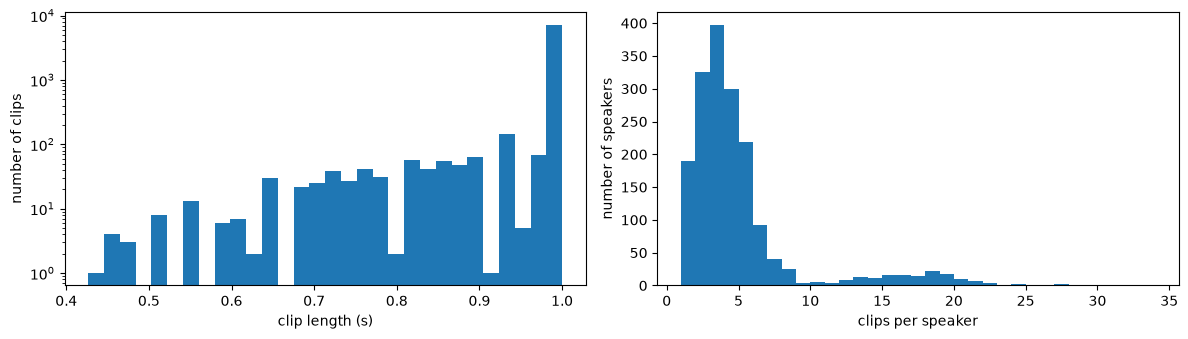

In [4]:
def load_waveform(path):
    # Read a WAV file and return its samples as a 1D float tensor with values between -1 and 1.
    audio, _ = tf.audio.decode_wav(tf.io.read_file(path), desired_channels=1)
    return tf.squeeze(audio, axis=-1)   # shape (samples, 1) -> (samples,)


lengths = np.array([len(load_waveform(p)) for p in file_paths])
clips_per_speaker = np.array(list(Counter(speakers).values()))

print(f'clips shorter than 1 s: {np.sum(lengths < SAMPLE_RATE)} of {len(lengths)}'
      f' (shortest: {lengths.min() / SAMPLE_RATE:.2f} s, longest: {lengths.max() / SAMPLE_RATE:.2f} s)')
print(f'clips per speaker: median {np.median(clips_per_speaker):.0f}, max {clips_per_speaker.max()}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(lengths / SAMPLE_RATE, bins=30)
axes[0].set_xlabel('clip length (s)')
axes[0].set_ylabel('number of clips')
axes[0].set_yscale('log')   # log scale, otherwise only the bar at 1.0 s is visible
axes[1].hist(clips_per_speaker, bins=range(1, clips_per_speaker.max() + 2))
axes[1].set_xlabel('clips per speaker')
axes[1].set_ylabel('number of speakers')
plt.tight_layout()
plt.show()

**Observations.** 822 of the 8000 clips (about 10%) are shorter than one second, the shortest only
0.43 s; these have to be padded (section 4.1). Most speakers recorded only a few clips (median 3), but
a small group recorded 15 to 20 clips, i.e. almost every word two or more times. If the data were
split randomly, the recordings of these speakers would end up in both the training and the test set.

One example of every command, as a waveform and as an audio player:

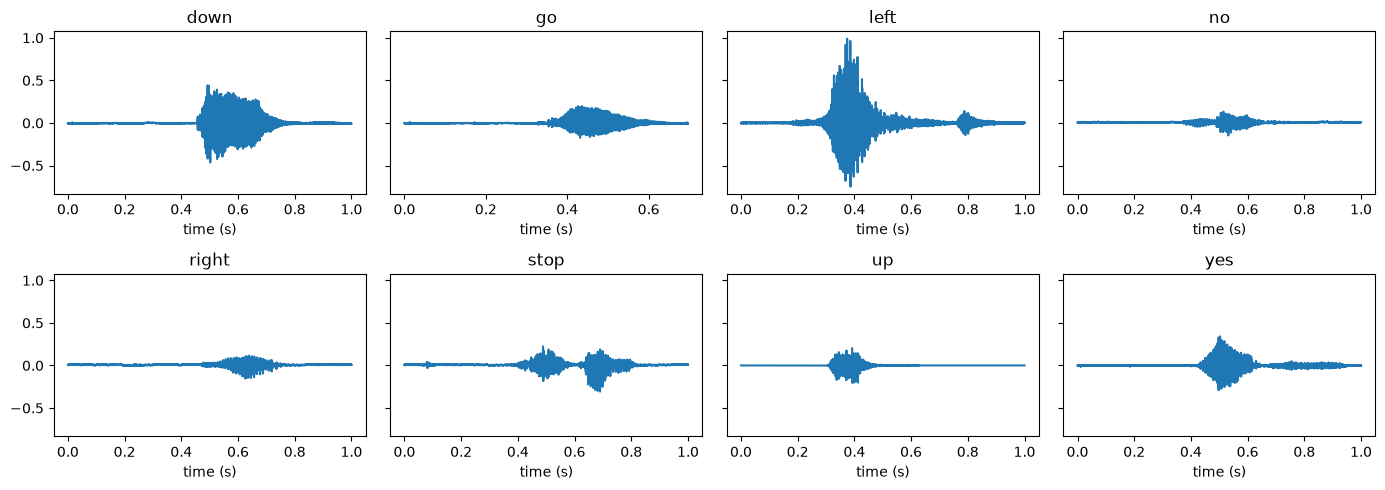

down


go


left


no


right


stop


up


yes


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharey=True)
examples = {}   # command -> waveform of its first clip, reused in section 4
for label, (command, ax) in enumerate(zip(COMMANDS, axes.flat)):
    examples[command] = load_waveform(file_paths[labels == label][0]).numpy()
    ax.plot(np.arange(len(examples[command])) / SAMPLE_RATE, examples[command])
    ax.set_title(command)
    ax.set_xlabel('time (s)')
plt.tight_layout()
plt.show()

for command, waveform in examples.items():
    print(command)
    display(Audio(waveform, rate=SAMPLE_RATE))

**Observations.** The word only fills a part of each clip, and its position varies (around 0.3 s for
*up*, around 0.6 s for *right*). The volume also differs a lot between speakers (compare *left* and
*no*). The clip of *go* is only 0.7 s long. These are exactly the variations the network must learn to
ignore.

### 3.2 Train / validation / test split

As explained in section 2.4, the split is made **by speaker**: the speakers are shuffled and divided
80 / 10 / 10 %, and every clip goes to the set of its speaker. The test set therefore only contains
voices the network has never heard, like a new passenger in the elevator.

The function receives a *group* for every clip. With the speaker as group, all clips of one speaker
stay together. With the file path as group, every clip is its own group, which gives the **random
split** of the TensorFlow tutorial; this is used for the comparison in section 6.

In [6]:
def split_by_group(groups, fractions=(0.8, 0.1, 0.1)):
    # Divide the clips into train / validation / test so that all clips of one group end up in the
    # same set. Returns three arrays with the positions of the clips in file_paths.
    unique_groups = np.unique(groups)
    np.random.default_rng(SEED).shuffle(unique_groups)
    n_train = int(fractions[0] * len(unique_groups))
    n_val = int(fractions[1] * len(unique_groups))
    train_groups = unique_groups[:n_train]
    val_groups = unique_groups[n_train:n_train + n_val]
    test_groups = unique_groups[n_train + n_val:]
    return (np.flatnonzero(np.isin(groups, train_groups)),
            np.flatnonzero(np.isin(groups, val_groups)),
            np.flatnonzero(np.isin(groups, test_groups)))


speaker_split = split_by_group(speakers)     # proposed: no speaker in more than one set
random_split = split_by_group(file_paths)    # alternative (TensorFlow tutorial): every clip on its own

# Check: no speaker appears in two sets of the speaker split
train_idx, val_idx, test_idx = speaker_split
assert not set(speakers[train_idx]) & set(speakers[val_idx])
assert not set(speakers[train_idx]) & set(speakers[test_idx])
assert not set(speakers[val_idx]) & set(speakers[test_idx])

# Number of clips per set and per command
print(f'{"":>6} ' + ' '.join(f'{c:>5}' for c in COMMANDS) + '  total  speakers')
for name, idx in zip(['train', 'val', 'test'], speaker_split):
    counts = np.bincount(labels[idx], minlength=len(COMMANDS))
    print(f'{name:>6} ' + ' '.join(f'{n:>5}' for n in counts)
          + f'  {len(idx):>5}  {len(set(speakers[idx])):>8}')

# How many test speakers were also heard during training?
for name, (tr, _, te) in [('speaker split', speaker_split), ('random split', random_split)]:
    seen = np.isin(speakers[te], speakers[tr]).mean()
    print(f'{name}: {seen:.0%} of the test clips are from a speaker that is also in the training set')

        down    go  left    no right  stop    up   yes  total  speakers
 train   790   820   794   791   793   795   787   780   6350      1400
   val   124    87   100   108   108    98   121   110    856       175
  test    86    93   106   101    99   107    92   110    794       175
speaker split: 0% of the test clips are from a speaker that is also in the training set
random split: 95% of the test clips are from a speaker that is also in the training set


**Observations.** The three sets contain 1400 / 175 / 175 speakers and roughly 80 / 10 / 10 % of
the clips; all commands are present in about equal numbers in every set, so accuracy is a fair
metric. The last two lines show why the split matters: with the speaker split no test clip comes from
a known voice, while with the random split of the TensorFlow tutorial **95%** of the test clips come
from a speaker whose voice is also in the training set. Section 6.5 measures whether this inflates the
test accuracy.

## 4. Preprocessing

The preprocessing follows the steps of section 2.2. Every step is a small function that works on
TensorFlow tensors, so that it can be used both on single clips (for plots and the demonstration) and
inside the `tf.data` pipeline.

### 4.1 Padding to one second

In [7]:
def pad_waveform(waveform):
    # Add zeros at the end so that every clip has exactly SAMPLE_RATE samples (1 second).
    waveform = waveform[:SAMPLE_RATE]   # no clip is longer, but this guarantees the length
    waveform = tf.pad(waveform, [[0, SAMPLE_RATE - tf.shape(waveform)[0]]])
    return tf.ensure_shape(waveform, [SAMPLE_RATE])   # tell TensorFlow the shape is now fixed

### 4.2 Spectrograms

Two representations are implemented:

- `stft_spectrogram`: the **linear STFT spectrogram** of the TensorFlow tutorial (the alternative in
  section 2.5): frames of 255 samples with a step of 128 samples, giving 124 frames × 129 frequency
  bins. As in the tutorial, no logarithm is applied.
- `log_mel_spectrogram`: the **log-Mel spectrogram** of Sainath & Parada (2015) (the proposed choice):
  windows of 25 ms (400 samples) with a step of 10 ms (160 samples), 40 Mel bands, and a logarithm,
  giving 98 frames × 40 Mel bands.

Both functions add a *channel* axis at the end, because a 2D convolution expects an image with
channels (like the R, G, B channels of a photo); a spectrogram is an image with one channel.

In [8]:
def stft_spectrogram(waveform):
    # Linear spectrogram as in the TensorFlow tutorial: (124 frames, 129 frequency bins, 1 channel).
    spectrogram = tf.abs(tf.signal.stft(waveform, frame_length=255, frame_step=128))
    return spectrogram[..., tf.newaxis]


FRAME_LENGTH = 400   # 25 ms window at 16 kHz (Sainath & Parada, 2015)
FRAME_STEP = 160     # 10 ms step
FFT_LENGTH = 512     # FFT size: the next power of 2 above 400, gives 257 frequency bins
NUM_MEL_BANDS = 40   # 40 log-Mel filterbanks (Sainath & Parada, 2015)

# Matrix that groups the 257 linear frequency bins into 40 Mel bands (narrow at low frequencies,
# wide at high frequencies). It is the same for every clip, so it is computed only once.
MEL_MATRIX = tf.signal.linear_to_mel_weight_matrix(
    num_mel_bins=NUM_MEL_BANDS,
    num_spectrogram_bins=FFT_LENGTH // 2 + 1,
    sample_rate=SAMPLE_RATE,
    lower_edge_hertz=20.0,
    upper_edge_hertz=SAMPLE_RATE / 2)   # up to the highest frequency in a 16 kHz recording


def log_mel_spectrogram(waveform):
    # Log-Mel spectrogram: (98 frames, 40 Mel bands, 1 channel).
    stft = tf.signal.stft(waveform, frame_length=FRAME_LENGTH, frame_step=FRAME_STEP,
                          fft_length=FFT_LENGTH)
    power = tf.abs(stft) ** 2              # energy per frequency bin: (98, 257)
    mel = tf.matmul(power, MEL_MATRIX)     # energy per Mel band:      (98, 40)
    log_mel = tf.math.log(mel + 1e-6)      # logarithm; the 1e-6 avoids log(0) in silent parts
    return log_mel[..., tf.newaxis]


example = pad_waveform(examples['up'])
print('waveform:', example.shape)
print('STFT spectrogram:', stft_spectrogram(example).shape)
print('log-Mel spectrogram:', log_mel_spectrogram(example).shape)

waveform: (16000,)
STFT spectrogram: (124, 129, 1)
log-Mel spectrogram: (98, 40, 1)


The three representations of the same clip (*up*). The STFT spectrogram is plotted with a logarithmic
colour scale, as in the tutorial, because otherwise almost everything is dark; the network itself
receives the values without logarithm.

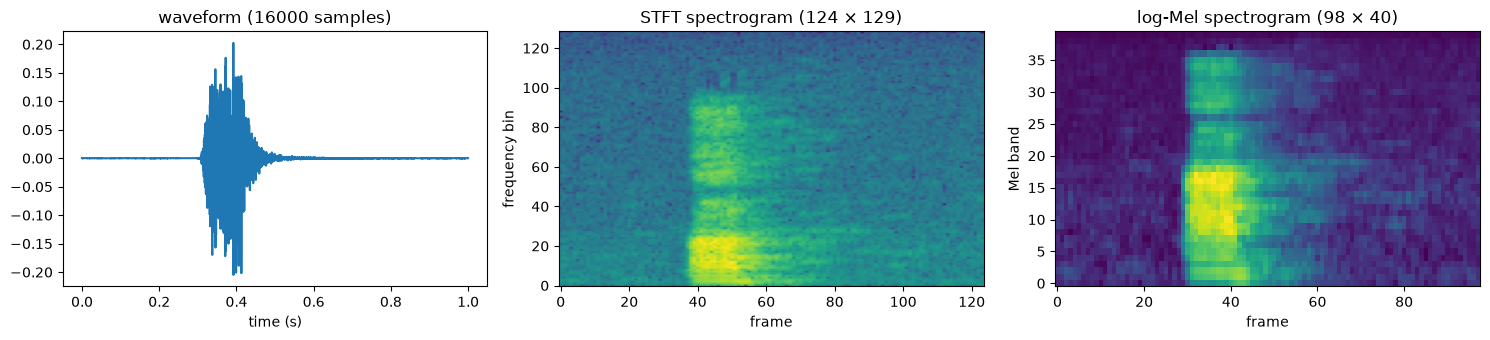

In [9]:
def plot_spectrogram(spectrogram, ax, title):
    # Time on the x-axis, frequency on the y-axis, low frequencies at the bottom.
    ax.imshow(np.squeeze(spectrogram, axis=-1).T, origin='lower', aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('frame')


fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(np.arange(SAMPLE_RATE) / SAMPLE_RATE, example)
axes[0].set_title('waveform (16000 samples)')
axes[0].set_xlabel('time (s)')
plot_spectrogram(np.log(stft_spectrogram(example) + 1e-6), axes[1], 'STFT spectrogram (124 × 129)')
axes[1].set_ylabel('frequency bin')
plot_spectrogram(log_mel_spectrogram(example), axes[2], 'log-Mel spectrogram (98 × 40)')
axes[2].set_ylabel('Mel band')
plt.tight_layout()
plt.show()

The log-Mel spectrogram of one example of every command:

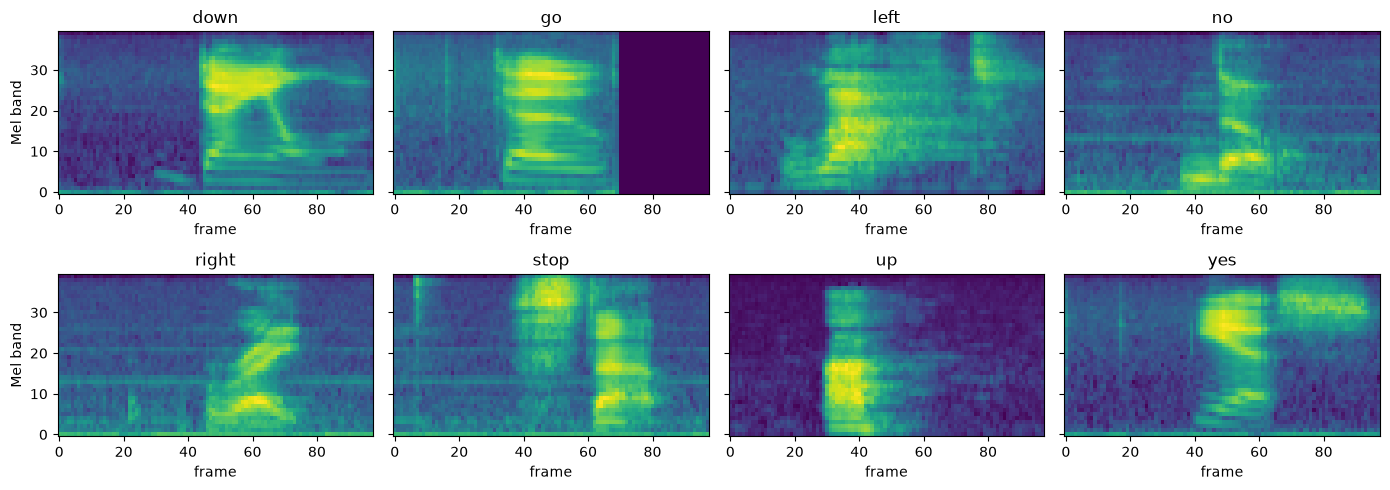

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharey=True)
for command, ax in zip(COMMANDS, axes.flat):
    plot_spectrogram(log_mel_spectrogram(pad_waveform(examples[command])), ax, command)
for ax in axes[:, 0]:
    ax.set_ylabel('Mel band')
plt.tight_layout()
plt.show()

**Observations.** Every command has its own pattern, which is what the CNN will learn to recognise.
*Stop* shows two separate parts (the hissing *st* high in the spectrum, followed by *op*), *yes* ends
with the *s* in the high Mel bands, and in *down* and *right* the vowel moves from one frequency to
another. The dark block at the end of *go* is the zero padding: since $\log(0 + 10^{-6})$ is a very low
value, padding looks like perfect silence. Compared to the STFT spectrogram, the log-Mel spectrogram
needs about 4 times fewer values (98 × 40 = 3 920 instead of 124 × 129 = 15 996) while the patterns
of the words stay clearly visible.

### 4.3 Input pipeline

`tf.data` reads the files, pads them and computes the spectrograms for a whole set. The spectrograms
are computed once and then kept in memory (`cache`), the training set is shuffled every epoch, and the
clips are grouped into batches of 64.

**Normalisation** (zero mean, unit variance) is not done here but as the first layer of the network
(section 5), because its mean and variance must be computed on the training set only.

In [11]:
BATCH_SIZE = 64


def make_dataset(indices, feature_fn, shuffle=False):
    # tf.data pipeline: file path -> waveform -> 1 second -> spectrogram, together with the label.
    ds = tf.data.Dataset.from_tensor_slices((file_paths[indices], labels[indices]))
    ds = ds.map(lambda path, label: (feature_fn(pad_waveform(load_waveform(path))), label),
                num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()   # compute the spectrograms only once
    if shuffle:
        ds = ds.shuffle(len(indices), seed=SEED)   # new order every epoch
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def make_datasets(split, feature_fn):
    # Train, validation and test dataset for one split and one representation.
    train_idx, val_idx, test_idx = split
    return (make_dataset(train_idx, feature_fn, shuffle=True),
            make_dataset(val_idx, feature_fn),
            make_dataset(test_idx, feature_fn))


# Proposed configuration: speaker split + log-Mel spectrogram
train_ds, val_ds, test_ds = make_datasets(speaker_split, log_mel_spectrogram)

for batch_spectrograms, batch_labels in train_ds.take(1):
    print('one batch of spectrograms:', batch_spectrograms.shape, '| labels:', batch_labels.shape)

one batch of spectrograms: (64, 98, 40, 1) | labels: (64,)


## 5. Implementation of the neural network

Both networks are built with the Keras `Sequential` API: a list of layers that the data passes through
one after the other. They share the same first and last layer:

- **Normalisation** (first layer): learns the mean and variance of the training spectrograms
  (`adapt`) and scales every input to mean 0 and variance 1 (section 2.2, step 3).
- **Dense layer with softmax** (last layer): one output per command, together a probability
  distribution over the 8 commands.

The functions receive the training dataset, because the normalisation must be adapted on it and the
input shape follows from it. This way, the same functions can be used in section 6 for the STFT
spectrogram and for the random split.

In [12]:
def make_normalization(train_ds):
    # Normalisation layer with the mean and variance of the training spectrograms (labels ignored).
    normalization = keras.layers.Normalization()
    normalization.adapt(train_ds.map(lambda spectrogram, label: spectrogram))
    return normalization


def input_shape_of(train_ds):
    # Shape of one spectrogram, e.g. (98, 40, 1); element_spec includes the batch dimension first.
    return train_ds.element_spec[0].shape[1:]

### 5.1 Baseline: fully connected network (DNN)

The baseline is the DNN of Sainath & Parada (2015): the spectrogram is flattened into one long vector
(98 × 40 = 3920 values), followed by **3 hidden layers of 128 ReLU units** and the softmax output.
Because every input value is connected to every neuron of the first hidden layer, most of the
parameters are in that layer.

In [13]:
def build_dnn(train_ds, seed=SEED):
    keras.utils.set_random_seed(seed)   # same seed -> same initial weights
    return keras.Sequential([
        keras.Input(shape=input_shape_of(train_ds)),
        make_normalization(train_ds),
        keras.layers.Flatten(),                         # (98, 40, 1) -> 3920 values
        keras.layers.Dense(128, activation='relu'),     # 3 hidden layers of 128 units
        keras.layers.Dense(128, activation='relu'),     # (Sainath & Parada, 2015)
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(len(COMMANDS), activation='softmax'),   # probability per command
    ], name='dnn')


dnn = build_dnn(train_ds)
dnn.summary()

Model: "dnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 98, 40, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       501,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,947 (2.04 MB)

 Trainable params: 535,944 (2.04 MB)

 Non-trainable params: 3 (16.00 B)

### Training

Both networks are trained the same way (section 2.4):

- **Adam** optimiser with the default learning rate (0.001) and the **cross-entropy** loss. The
  *sparse* variant is used because the labels are numbers (0–7) instead of one-hot vectors.
- At most 50 epochs, with **early stopping**: training stops when the validation loss has not improved
  for 5 epochs, and the weights of the best epoch are restored. The patience of 5 (instead of 2 in the
  TensorFlow tutorial) gives the network some room, because the validation loss is noisy with only 856
  validation clips.

Epoch 1/50


100/100 - 1s - 8ms/step - accuracy: 0.4184 - loss: 1.5226 - val_accuracy: 0.5794 - val_loss: 1.1076


Epoch 2/50


100/100 - 0s - 3ms/step - accuracy: 0.6235 - loss: 1.0131 - val_accuracy: 0.6717 - val_loss: 0.8983


Epoch 3/50


...

100/100 - 0s - 4ms/step - accuracy: 0.8474 - loss: 0.4225 - val_accuracy: 0.7675 - val_loss: 0.7256


Epoch 9/50


100/100 - 0s - 4ms/step - accuracy: 0.8644 - loss: 0.3632 - val_accuracy: 0.7827 - val_loss: 0.6602


Epoch 10/50


100/100 - 0s - 4ms/step - accuracy: 0.8757 - loss: 0.3409 - val_accuracy: 0.7804 - val_loss: 0.7042


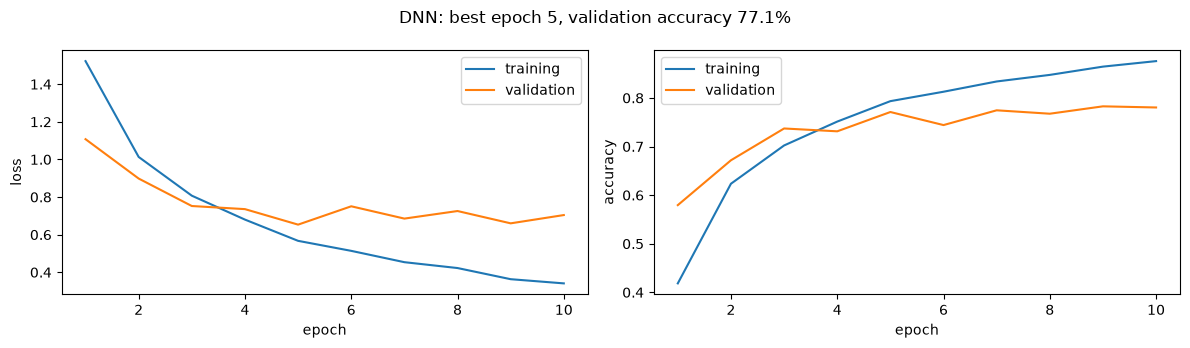

In [14]:
EPOCHS = 50


def train(model, train_ds, val_ds, verbose=2):
    # Train a model with Adam and cross-entropy until the validation loss stops improving.
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=['accuracy'])
    early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                                   restore_best_weights=True)
    return model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                     callbacks=[early_stopping], verbose=verbose,
                     shuffle=False)   # train_ds is already shuffled by make_dataset


def plot_history(history, title):
    # Learning curves: loss and accuracy per epoch, on the training and on the validation set.
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    epochs = np.arange(1, len(history.history['loss']) + 1)   # epochs are counted from 1
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        ax.plot(epochs, history.history[metric], label='training')
        ax.plot(epochs, history.history['val_' + metric], label='validation')
        ax.set_xlabel('epoch')
        ax.set_ylabel(metric)
        ax.legend()
    best = np.argmin(history.history['val_loss'])   # the epoch restored by early stopping
    fig.suptitle(f'{title}: best epoch {best + 1}, '
                 f'validation accuracy {history.history["val_accuracy"][best]:.1%}')
    plt.tight_layout()
    plt.show()


dnn_history = train(dnn, train_ds, val_ds)
plot_history(dnn_history, 'DNN')

**Observations.** The DNN learns fast but reaches its best validation loss already in epoch 5 (77.1%
validation accuracy). After that, the training accuracy keeps rising (to 88%) while the validation loss
goes up again: the network starts to **overfit**, i.e. to memorise the training speakers instead of
learning patterns that also hold for new voices. Early stopping ends the training in epoch 10 and
restores the weights of epoch 5. With 94% of its 536K parameters in the first layer, where every one of
the 3920 inputs is connected to every neuron, the DNN has to learn each pattern separately for every
position in the spectrogram, which is exactly the weakness pointed out by Sainath & Parada (2015).

### 5.2 Proposed model: convolutional neural network (CNN)

The CNN follows the ideas of Sainath & Parada (2015) and the layer types of the TensorFlow tutorial:

- **Three convolution blocks.** Each block has a convolution with 3 × 3 filters (3 frames × 3 Mel
  bands) and ReLU, followed by **max-pooling of 2 × 2**, which halves the spectrogram in time *and* in
  frequency (pooling in both directions worked best in Sainath & Parada). `padding='same'` keeps the
  size during the convolution, so only the pooling shrinks it: 98 × 40 → 49 × 20 → 24 × 10 → 12 × 5.
  The first block has 32 filters, the others 64: deeper layers combine simple patterns into more
  complex ones, so they need more filters.
- **Dense layer of 64 units** on the 12 × 5 × 64 = 3840 values of the last block, followed by the
  softmax output.
- **Dropout** after the convolutions (25%) and after the dense layer (50%), as in the tutorial.

The third block is not in the tutorial. Without it, the dense layer would receive 24 × 10 × 64 =
15 360 values and need about 2 million weights; with it, the whole CNN is smaller than the DNN,
in line with the small-footprint goal of Sainath & Parada.

In [15]:
def build_cnn(train_ds, seed=SEED):
    keras.utils.set_random_seed(seed)   # same seed -> same initial weights
    return keras.Sequential([
        keras.Input(shape=input_shape_of(train_ds)),
        make_normalization(train_ds),
        # block 1: 32 filters of 3x3, then halve time and frequency: (98, 40) -> (49, 20)
        keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        # block 2: 64 filters: (49, 20) -> (24, 10)
        keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        # block 3: 64 filters: (24, 10) -> (12, 5)
        keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        keras.layers.MaxPooling2D(2),
        keras.layers.Dropout(0.25),                     # switch off 25% of the values in training
        keras.layers.Flatten(),                         # 12 x 5 x 64 = 3840 values
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(len(COMMANDS), activation='softmax'),   # probability per command
    ], name='cnn')


cnn = build_cnn(train_ds)
cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 98, 40, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 98, 40, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 49, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 5, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3840)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       245,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 302,091 (1.15 MB)

 Trainable params: 302,088 (1.15 MB)

 Non-trainable params: 3 (16.00 B)

Epoch 1/50


100/100 - 13s - 130ms/step - accuracy: 0.3052 - loss: 1.7601 - val_accuracy: 0.6145 - val_loss: 1.1372


Epoch 2/50


100/100 - 11s - 108ms/step - accuracy: 0.5452 - loss: 1.2238 - val_accuracy: 0.7488 - val_loss: 0.7564


Epoch 3/50


...

100/100 - 10s - 100ms/step - accuracy: 0.9153 - loss: 0.2258 - val_accuracy: 0.9077 - val_loss: 0.3083


Epoch 18/50


100/100 - 10s - 104ms/step - accuracy: 0.9231 - loss: 0.2182 - val_accuracy: 0.9077 - val_loss: 0.2814


Epoch 19/50


100/100 - 10s - 104ms/step - accuracy: 0.9164 - loss: 0.2214 - val_accuracy: 0.9065 - val_loss: 0.2997


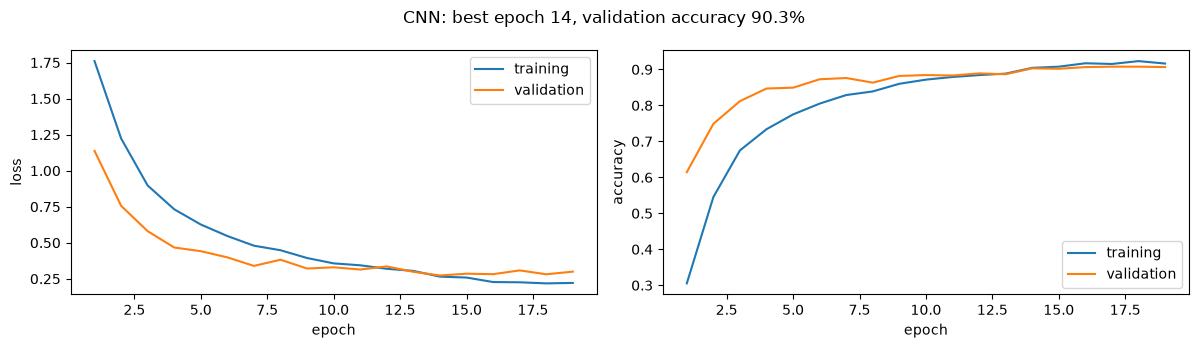

In [16]:
cnn_history = train(cnn, train_ds, val_ds)
plot_history(cnn_history, 'CNN')

**Observations.** The CNN reaches **90.3%** validation accuracy (best epoch 14), 13 percentage points
more than the DNN, with **44% fewer parameters** (302K against 536K). The training and validation
curves stay close together, so the CNN hardly overfits: weight sharing and dropout prevent it from
memorising the training speakers. (In the first epochs the training accuracy is even below the
validation accuracy, because dropout is only active during training.) This confirms the finding of
Sainath & Parada (2015) on our data: a CNN is more accurate than a DNN of the same or larger size.

The price is computation: one training epoch of the CNN takes about 4–5 seconds against less than
one second for the DNN, because every filter is applied at every position of the spectrogram. Sainath &
Parada mention the same trade-off (their CNN needs 9.7 million multiplications per input). For one
spectrogram, this is still only a few milliseconds, as measured in section 6.

These numbers are measured on the validation set, which was also used for early stopping. The final,
unbiased evaluation on the test set follows in section 6.

## 6. Evaluation

The evaluation has two parts:

1. **The proposed model on the test set (6.1).** The CNN of section 5.2 is evaluated once on the test
   set, which was not used for training or early stopping, with the metrics of section 2.4: accuracy,
   precision / recall / F1 per command, the confusion matrix, the size of the model and the time it
   needs per command.
2. **The alternatives (6.2–6.5).** The three questions of section 2.5 are answered by changing one
   component of the proposed solution at a time. Like a GA run in assignment 1, training a network is
   random (initial weights, dropout), so a single training run could be lucky or unlucky. Every
   configuration is therefore trained `NUMBER_OF_RUNS` times with a different seed, and the mean and
   standard deviation of the test accuracy are compared.

### 6.1 The proposed model on the test set

In [17]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# True labels of the test set (test_ds is not shuffled, so the order matches the predictions)
y_true = np.concatenate([batch_labels for _, batch_labels in test_ds])
# Predicted command = the command with the highest probability
y_pred = np.argmax(cnn.predict(test_ds, verbose=0), axis=1)

print(f'test accuracy: {np.mean(y_true == y_pred):.1%} ({np.sum(y_true == y_pred)} of {len(y_true)} clips)\n')
print(classification_report(y_true, y_pred, target_names=COMMANDS, digits=3))

test accuracy: 92.3% (733 of 794 clips)

              precision    recall  f1-score   support

        down      0.929     0.907     0.918        86
          go      0.872     0.806     0.838        93
        left      0.935     0.953     0.944       106
          no      0.826     0.891     0.857       101
       right      0.979     0.960     0.969        99
        stop      0.980     0.916     0.947       107
          up      0.891     0.978     0.933        92
         yes      0.972     0.964     0.968       110

    accuracy                          0.923       794
   macro avg      0.923     0.922     0.922       794
weighted avg      0.925     0.923     0.923       794



**Observations.** On the 794 test clips of 175 speakers the network has never heard, the CNN classifies
**92.3%** of the commands correctly (733 clips). This is in line with the validation accuracy (90.3%):
the difference of 2 points is within what can be expected between two different groups of speakers.
Precision and recall are high for all commands, but not equal:

- *yes*, *right*, *stop* and *left* are recognised best (F1 ≥ 0.94);
- *go* is the weakest command (recall 0.81, F1 0.84), followed by *no* (precision 0.83).

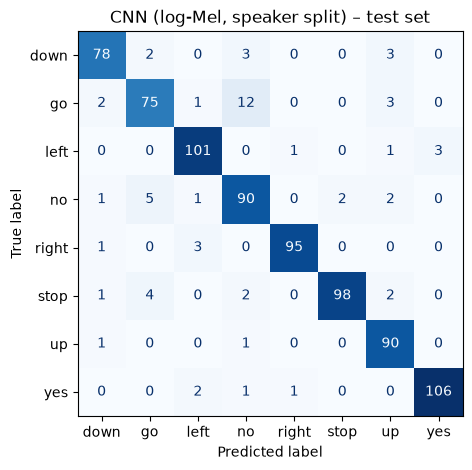

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=COMMANDS, ax=ax,
                                        cmap='Blues', colorbar=False)
ax.set_title('CNN (log-Mel, speaker split) – test set')
plt.show()

**Observations.** The confusion matrix shows where the errors come from. By far the most frequent
mistake is ***go* recognised as *no*** (12 times), and *no* is also recognised as *go* 5 times. Both are
short words with the same vowel; they only differ in the first consonant (*g* versus *n*), which is
short and quiet compared to the vowel. All other confusions occur at most 5 times.

For the elevator this is relevant in two ways:

- The confusion that would be most annoying for a passenger, *up* versus *down*, is rare: 3 of the 86
  *down* clips were recognised as *up*, and 1 of the 92 *up* clips as *down*.
- *go* (start) and *no* (cancel) have opposite meanings in an elevator. A real product should use
  command words that sound clearly different, and should not act on uncertain predictions
  (section 7.1).

For comparison with the literature: Warden (2018) reports 88.2% for the baseline CNN on the full
Speech Commands task and the TensorFlow tutorial reports 83.3% on this dataset. Neither number is
directly comparable (the full task has 12 classes including *unknown* and *silence*; the tutorial uses
a different model and a random split), but they show that the result of the proposed CNN is in a
realistic range.

**Size and speed.** For the elevator, the model must be small and react quickly. The size is the number
of parameters × 4 bytes (32-bit floats). The time is measured for one command as it would arrive in the
elevator: one clip, preprocessing (padding + log-Mel spectrogram) and prediction, averaged over 100
clips.

In [19]:
def time_per_command(model, feature_fn, n=100):
    # Average time in milliseconds to preprocess and classify one clip (batch of 1).
    waveforms = [load_waveform(p) for p in file_paths[test_idx[:n]]]
    model(feature_fn(pad_waveform(waveforms[0]))[tf.newaxis], training=False)   # warm-up
    start = time.perf_counter()
    for waveform in waveforms:
        spectrogram = feature_fn(pad_waveform(waveform))[tf.newaxis]   # add batch dimension
        model(spectrogram, training=False)
    return (time.perf_counter() - start) / n * 1000


for name, model in [('DNN', dnn), ('CNN', cnn)]:
    print(f'{name}: {model.count_params():>7,} parameters = {model.count_params() * 4 / 1024:6.0f} KB, '
          f'{time_per_command(model, log_mel_spectrogram):.1f} ms per command')

DNN: 535,947 parameters =   2094 KB, 5.5 ms per command


CNN: 302,091 parameters =   1180 KB, 6.9 ms per command


**Observations.** The CNN needs 1.2 MB for its weights, the DNN 2.1 MB. Both process a command
(preprocessing and prediction) in a few milliseconds on a laptop CPU; the CNN is slightly slower
because of its convolutions, as discussed in section 5.2. Even on a much slower embedded processor in
the elevator, this leaves a large margin before a passenger would notice a delay. The size could be
reduced further by storing the weights as 8-bit integers instead of 32-bit floats (a factor 4).

### 6.2 Setup of the experiments

`run_experiment` trains one configuration `NUMBER_OF_RUNS` times (seeds 42, 43, ...) and evaluates
every trained network on the test set of its split. All other settings are those of the proposed
solution, so only the component under test changes. Three runs per configuration keep the total
training time reasonable on a laptop CPU; the standard deviation shows whether a difference between
two configurations is larger than the variation between runs.

In [20]:
NUMBER_OF_RUNS = 3


def run_experiment(name, build_model=build_cnn, feature_fn=log_mel_spectrogram, split=speaker_split):
    # Train a configuration NUMBER_OF_RUNS times and collect its test accuracy.
    train_ds, val_ds, test_ds = make_datasets(split, feature_fn)
    accuracies, best_epochs = [], []
    start = time.perf_counter()
    for run in range(NUMBER_OF_RUNS):
        model = build_model(train_ds, seed=SEED + run)
        history = train(model, train_ds, val_ds, verbose=0)
        accuracies.append(model.evaluate(test_ds, verbose=0)[1])   # [loss, accuracy]
        best_epochs.append(np.argmin(history.history['val_loss']) + 1)
    result = {'name': name,
              'parameters': model.count_params(),
              'accuracies': np.array(accuracies),
              'best_epoch': np.mean(best_epochs),
              'minutes_per_run': (time.perf_counter() - start) / NUMBER_OF_RUNS / 60}
    print(f'{name}: test accuracy {result["accuracies"].mean():.1%} ± {result["accuracies"].std():.1%} '
          f'(runs: {", ".join(f"{a:.1%}" for a in accuracies)})')
    return result


def show_results(results, title):
    # Table and bar chart (mean test accuracy, error bar = standard deviation) of some experiments.
    print(f'\n{"configuration":<34} {"parameters":>10} {"test accuracy":>16} {"best epoch":>11} {"min/run":>8}')
    for r in results:
        print(f'{r["name"]:<34} {r["parameters"]:>10,} '
              f'{r["accuracies"].mean():>9.1%} ± {r["accuracies"].std():.1%} '
              f'{r["best_epoch"]:>11.1f} {r["minutes_per_run"]:>8.1f}')
    names = [r['name'] for r in results]
    means = [r['accuracies'].mean() for r in results]
    stds = [r['accuracies'].std() for r in results]
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(results) + 1))
    ax.barh(names, means, xerr=stds, capsize=4)
    for i, mean in enumerate(means):
        ax.text(mean + 0.01, i, f'{mean:.1%}', va='center')
    ax.set_xlim(0.5, 1.0)
    ax.invert_yaxis()   # first configuration on top
    ax.set_xlabel(f'test accuracy (mean of {NUMBER_OF_RUNS} runs)')
    ax.set_title(title)
    plt.show()


result_proposed = run_experiment('CNN, log-Mel, speaker split')

CNN, log-Mel, speaker split: test accuracy 93.5% ± 1.0% (runs: 92.2%, 94.3%, 94.1%)


**Observations.** The three runs of the proposed configuration reach 92.2%, 94.3% and 94.1%, so the
test accuracy varies by about **±1 percentage point** between runs only because of the random
initialisation and dropout. Differences between configurations smaller than this should not be
over-interpreted. (The run with seed 42 is the same configuration as the model of section 5.2, but
differs by one clip from section 6.1, because multi-threaded computations on the CPU are not exactly
reproducible.)

### 6.3 Architecture: CNN versus DNN

Is the CNN better than the DNN baseline, as found by Sainath & Parada (2015)?

DNN, log-Mel, speaker split: test accuracy 80.3% ± 0.3% (runs: 80.5%, 79.8%, 80.6%)

configuration                      parameters    test accuracy  best epoch  min/run
CNN, log-Mel, speaker split           302,091     93.5% ± 1.0%        20.3      4.6
DNN, log-Mel, speaker split           535,947     80.3% ± 0.3%         7.7      0.1


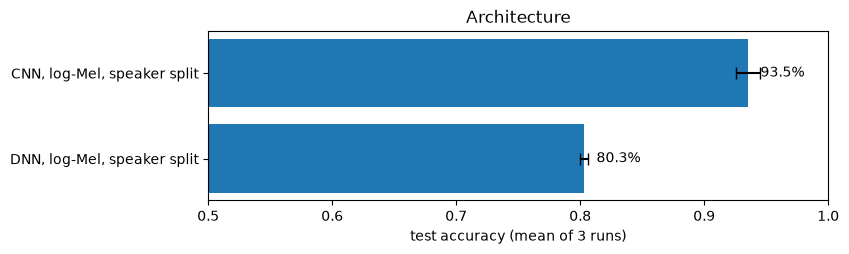

In [21]:
result_dnn = run_experiment('DNN, log-Mel, speaker split', build_model=build_dnn)
show_results([result_proposed, result_dnn], 'Architecture')

**Interpretation.** The CNN is **13 percentage points** better than the DNN (93.5% versus 80.3%),
far more than the variation between runs, while the DNN has 1.8 times more parameters. The DNN reaches
its best validation loss after only 8 epochs on average and then overfits (section 5.1). This
confirms the conclusion of Sainath & Parada (2015) on our data: because a CNN uses the time-frequency
structure of the spectrogram and is robust to small shifts, it is clearly more accurate than a fully
connected network of the same or larger size. The only advantage of the DNN is its training and
computation time, which is irrelevant for a model that is trained once and then only has to classify
one command at a time.

### 6.4 Preprocessing: log-Mel versus STFT spectrogram

The same CNN on the linear STFT spectrogram of the TensorFlow tutorial (124 × 129 instead of 98 × 40).

CNN, STFT, speaker split: test accuracy 91.5% ± 0.7% (runs: 92.4%, 91.1%, 90.9%)

configuration                      parameters    test accuracy  best epoch  min/run
CNN, log-Mel, speaker split           302,091     93.5% ± 1.0%        20.3      4.6
CNN, STFT, speaker split            1,039,371     91.5% ± 0.7%        17.7     18.3


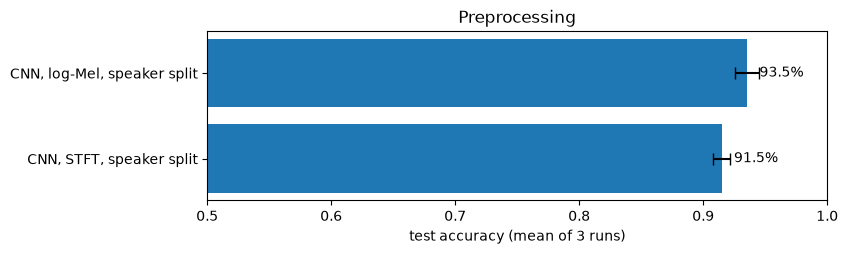

In [22]:
result_stft = run_experiment('CNN, STFT, speaker split', feature_fn=stft_spectrogram)
show_results([result_proposed, result_stft], 'Preprocessing')

**Interpretation.** With the log-Mel spectrogram, the CNN is about **2 percentage points** more
accurate than with the linear STFT spectrogram of the tutorial (93.5% versus 91.5%). The difference is
small compared to the variation between runs, but consistent: the worst log-Mel run (92.2%) is about as
good as the best STFT run (92.4%). The larger advantage is in the **cost**: the STFT spectrogram has 4
times more values (124 × 129 instead of 98 × 40), so the same CNN needs **3.4 times more parameters**
(1.04 million, almost all in the dense layer) and training takes 4 times longer. The Mel scale and
the logarithm keep the information that matters for speech and remove what does not, which gives an
equally good or better model at a fraction of the size. (Since the STFT variant follows the tutorial
without a logarithm, this compares the two complete preprocessing pipelines, not the Mel scale alone.)

### 6.5 Data split: by speaker versus random

The same CNN, trained and tested on the random split of the TensorFlow tutorial, in which 95% of the
test clips come from a speaker that is also in the training set (section 3.2).

CNN, log-Mel, random split: test accuracy 91.8% ± 0.4% (runs: 91.8%, 92.3%, 91.3%)

configuration                      parameters    test accuracy  best epoch  min/run
CNN, log-Mel, speaker split           302,091     93.5% ± 1.0%        20.3      4.6
CNN, log-Mel, random split            302,091     91.8% ± 0.4%        18.7      4.4


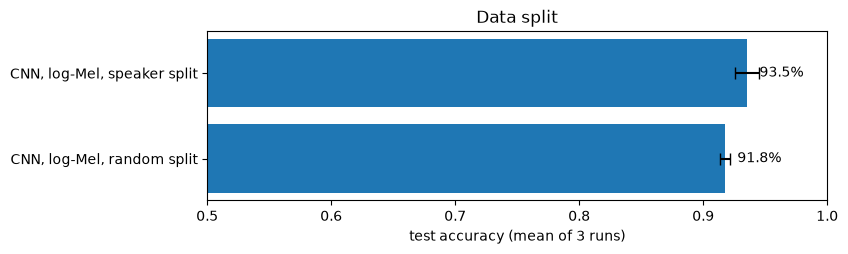

In [23]:
result_random = run_experiment('CNN, log-Mel, random split', split=random_split)
show_results([result_proposed, result_random], 'Data split')

**Interpretation.** The result is the opposite of what was expected in section 2.4: with the random
split, the test accuracy is not higher but slightly *lower* (91.8% versus 93.5%). The cell below
confirms that the random split does leak information: 43% of its test clips were spoken by a speaker
who said *the same word* in the training set.

In [ ]:
# How many test clips of the random split come from a speaker who said the same word in training?
for name, (tr, _, te) in [('speaker split', speaker_split), ('random split', random_split)]:
    train_pairs = set(zip(speakers[tr], labels[tr]))   # (speaker, command) pairs seen in training
    same_word = np.mean([(s, l) in train_pairs for s, l in zip(speakers[te], labels[te])])
    print(f'{name}: {same_word:.0%} of the test clips: same speaker, same word as in the training set')

speaker split: 0% of the test clips: same speaker, same word as in the training set
random split: 43% of the test clips: same speaker, same word as in the training set


Even so, the network does not profit from this measurably. Two reasons explain this:

1. **The two splits have different test sets.** With about 800 test clips, the accuracy itself has a
   statistical uncertainty of about ±1 point (standard error $\sqrt{0.93 \cdot 0.07 / 800} \approx 0.9\%$),
   so one test set can simply be a bit easier than another. A difference of 1.7 points between two
   different test sets is not enough to conclude anything.
2. **The CNN hardly overfits** (section 5.2): it learns the patterns of the words rather than the voices
   of individual speakers, so having heard a voice before gives little advantage.

The conclusion is therefore that the speaker leakage did **not** measurably inflate the accuracy on
this dataset, and the hypothesis of section 2.5 is not confirmed. The speaker split is still the
correct method for SLIFTS: it is the only one that measures the real situation in the elevator, where
every passenger is a new voice, and it costs nothing. With models that overfit more, or datasets with
many repetitions per speaker, the effect of leakage can be larger, which is why the reference
implementation of the Speech Commands dataset keeps the recordings of one speaker together.

### 6.6 Summary


configuration                      parameters    test accuracy  best epoch  min/run
CNN, log-Mel, speaker split           302,091     93.5% ± 1.0%        20.3      4.6
DNN, log-Mel, speaker split           535,947     80.3% ± 0.3%         7.7      0.1
CNN, STFT, speaker split            1,039,371     91.5% ± 0.7%        17.7     18.3
CNN, log-Mel, random split            302,091     91.8% ± 0.4%        18.7      4.4


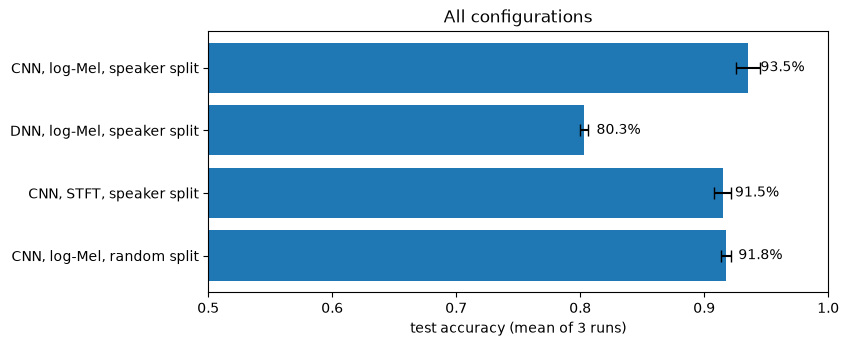

In [24]:
show_results([result_proposed, result_dnn, result_stft, result_random], 'All configurations')

**Interpretation.** The proposed configuration (CNN, log-Mel spectrogram, speaker split) is the best of
the four. The choice of **architecture** has by far the largest effect (13 points); the choice of
**preprocessing** affects the accuracy a little (2 points) but the size of the model a lot (factor
3.4); the **data split** did not change the measured accuracy on this dataset, but determines whether
the measurement can be trusted for new passengers.

## 7. Demonstration

The demonstration turns the trained CNN of section 5.2 into a small "elevator controller": a spoken
command goes in, an elevator action comes out.

### 7.1 From prediction to elevator action

The network always outputs one of the 8 commands, even when it is unsure. In the elevator, a wrong
action is worse than no action (section 1.2), so the controller only acts when the network is confident
enough: if the highest probability is below a **confidence threshold**, it asks the passenger to repeat
the command. *left* and *right* are recognised but ignored, since they have no meaning in an elevator.

The table below shows the effect of the threshold on the test set: how many commands are accepted,
how accurate the accepted commands are, and how many test clips lead to a wrong action.

In [25]:
probabilities = cnn.predict(test_ds, verbose=0)   # one row of 8 probabilities per test clip
confidence = probabilities.max(axis=1)
correct = np.argmax(probabilities, axis=1) == y_true

print(f'{"threshold":>9} {"accepted":>9} {"accuracy of accepted":>21} {"wrong actions":>14}')
for threshold in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    accepted = confidence >= threshold
    print(f'{threshold:>9.2f} {accepted.mean():>9.1%} {correct[accepted].mean():>21.1%} '
          f'{(accepted & ~correct).mean():>14.1%}')

threshold  accepted  accuracy of accepted  wrong actions
     0.00    100.0%                 92.3%           7.7%
     0.50     97.6%                 93.9%           5.9%
     0.60     93.7%                 95.7%           4.0%
     0.70     90.9%                 96.0%           3.7%
     0.80     86.8%                 97.5%           2.1%
     0.90     81.2%                 98.9%           0.9%
     0.95     76.1%                 99.0%           0.8%


**Observations.** Without a threshold, 7.7% of the commands lead to a wrong action. A threshold of
**0.8** reduces this to **2.1%** (almost 4 times fewer), because most errors are made with a low
probability: the accepted commands are 97.5% correct. The price is that 13% of the commands are not
accepted and the passenger has to repeat them. A threshold of 0.9 brings the wrong actions below 1%,
but then almost one in five commands has to be repeated. The controller below uses 0.8 as a balance;
SLIFTS can tune this value to the cost of a wrong action in practice.

In [26]:
CONFIDENCE_THRESHOLD = 0.8   # below this probability the elevator asks to repeat the command

# What the elevator does for every command (None = not an elevator command)
ELEVATOR_ACTIONS = {
    'up': 'going up',
    'down': 'going down',
    'stop': 'stopping at the next floor',
    'go': 'closing the doors and starting',
    'yes': 'confirmed',
    'no': 'cancelled',
    'left': None,
    'right': None,
}


def recognise(waveform, model=cnn):
    # Preprocess one clip exactly as in training and return (command, probability).
    spectrogram = log_mel_spectrogram(pad_waveform(waveform))[tf.newaxis]   # add batch dimension
    probabilities = model(spectrogram, training=False).numpy()[0]
    return COMMANDS[np.argmax(probabilities)], probabilities.max()


def elevator_response(command, confidence):
    # Decide what the elevator does with a recognised command.
    if confidence < CONFIDENCE_THRESHOLD:
        return 'not sure, please repeat the command'
    if ELEVATOR_ACTIONS[command] is None:
        return f'"{command}" is not an elevator command, ignored'
    return ELEVATOR_ACTIONS[command]

### 7.2 Commands from the test set

Ten random clips from the test set, i.e. from speakers the network has never heard:

In [27]:
rng = np.random.default_rng(SEED)
for index in rng.choice(test_idx, size=10, replace=False):
    waveform = load_waveform(file_paths[index])
    command, probability = recognise(waveform)
    print(f'said "{COMMANDS[labels[index]]}" -> heard "{command}" ({probability:.0%}) '
          f'-> elevator: {elevator_response(command, probability)}')
    display(Audio(waveform.numpy(), rate=SAMPLE_RATE))

said "down" -> heard "down" (99%) -> elevator: going down


said "up" -> heard "up" (98%) -> elevator: going up


said "down" -> heard "down" (99%) -> elevator: going down


said "stop" -> heard "stop" (100%) -> elevator: stopping at the next floor


said "no" -> heard "no" (100%) -> elevator: cancelled


said "no" -> heard "no" (90%) -> elevator: cancelled


said "stop" -> heard "stop" (100%) -> elevator: stopping at the next floor


said "down" -> heard "down" (68%) -> elevator: not sure, please repeat the command


said "go" -> heard "go" (100%) -> elevator: closing the doors and starting


said "up" -> heard "up" (99%) -> elevator: going up


**Observations.** Nine of the ten commands are recognised with a probability of 90% or more and lead
to the right action. For one *down* clip the network is only 68% sure; although the prediction is
correct, the controller asks the passenger to repeat the command instead of risking a wrong action.
This is exactly the behaviour designed in section 7.1.

### 7.3 Live command from the microphone

The function `listen` records two seconds from the microphone (with the `sounddevice` library), so that the
speaker does not have to time the command exactly. From the recording, the one-second window with the
most energy is kept, the same idea as the *Extract Loudest Section* tool that was used to cut the clips
of the dataset (Warden, 2018). The cumulative sum makes it possible to compute the energy of every
window at once.

Set `LIVE_DEMO = True` and run the cell to try it.

In [28]:
LIVE_DEMO = False   # set to True to speak a command into the microphone


def loudest_second(recording):
    # Return the 1-second window of the recording with the most energy (sum of squared samples).
    energy = np.concatenate([[0], np.cumsum(recording ** 2)])
    window_energy = energy[SAMPLE_RATE:] - energy[:-SAMPLE_RATE]   # energy of every 1 s window
    start = np.argmax(window_energy)
    return recording[start:start + SAMPLE_RATE]


def listen(seconds=2):
    # Record from the default microphone at 16 kHz, mono, and keep the loudest second.
    import sounddevice as sd
    print('Speak now...')
    recording = sd.rec(int(seconds * SAMPLE_RATE), samplerate=SAMPLE_RATE, channels=1, dtype='float32')
    sd.wait()   # block until the recording is finished
    return loudest_second(recording.flatten())


# Check of loudest_second: a short loud burst in silence must be found
test_recording = np.zeros(2 * SAMPLE_RATE, dtype='float32')
test_recording[25000:26000] = 1.0
assert np.sum(loudest_second(test_recording)) == 1000

if LIVE_DEMO:
    waveform = listen()
    display(Audio(waveform, rate=SAMPLE_RATE))
    command, probability = recognise(tf.constant(waveform))
    print(f'heard "{command}" ({probability:.0%}) -> elevator: {elevator_response(command, probability)}')

## 8. Advice to SLIFTS and conclusion

### 8.1 Advice

SLIFTS asked how speech commands should be pre-processed and which neural network architecture is
suitable. Based on the research in section 2 and the evaluation in section 6, the advice is:

| Component | Advice | Why |
|---|---|---|
| **Preprocessing** | Pad every clip to 1 second, convert it into a **log-Mel spectrogram** (40 Mel bands, 25 ms windows, 10 ms step) and normalise it | 4 times fewer values than a plain spectrogram, matches human hearing, 2 points more accurate and 3.4 times smaller model (section 6.4) |
| **Architecture** | A small **2D convolutional neural network**: three blocks of convolution + max-pooling, one dense layer, dropout, softmax output | 93.5% on speakers it has never heard, 13 points better than a fully connected network with 1.8 times more parameters (section 6.3); 1.2 MB, a few ms per command (section 6.1) |
| **Decision rule** | Only act when the network is at least **80% confident**, otherwise ask the passenger to repeat | Reduces wrong actions from 7.7% to 2.1% (section 7.1) |
| **Evaluation** | Always test on **speakers that are not in the training data** | The only way to measure the situation in the elevator (section 6.5) |

**Alternatives.** A fully connected network is simpler and cheaper to compute, but clearly less
accurate. The STFT spectrogram of the TensorFlow tutorial works almost as well, but needs a model that
is 3.4 times larger. Recurrent networks and pre-trained models (section 2.3) were not tested; they are
an option if the vocabulary grows or if the commands become longer phrases, but they are larger and
harder to run on a small device.

### 8.2 Limitations and next steps

This proof of concept shows that the approach works, but it was evaluated under clean conditions. Before
it can be used in an elevator, the following steps are needed:

1. **Own vocabulary and data.** The dataset contains only 8 words, two of which are useless in an
   elevator, while floor numbers and *open* / *close* are missing. SLIFTS needs its own recordings
   from many different speakers, ideally recorded inside elevators. The words should sound clearly
   different from each other: *go* and *no* were the most confused pair (section 6.1).
2. **Unknown words and silence.** The network always picks one of its commands, even when someone just
   talks or nothing is said. A real system needs extra classes for *unknown word* and *silence*, as in
   the standard Speech Commands task (Warden, 2018).
3. **Continuous audio.** In the elevator, the microphone delivers a continuous stream instead of
   one-second clips. Warden (2018) shows how much harder this is: the same baseline that scored 88% on
   clips correctly recognised only 46% of the words in a continuous recording. The system must be
   evaluated in this streaming setting, and probably needs a wake word.
4. **Noise.** Elevator noise (motor, doors, other passengers) was not part of the data. Following
   Sainath & Parada (2015), the training clips should be mixed with recorded elevator noise at
   different volumes.
5. **Deployment.** The 1.2 MB model can be made 4 times smaller by storing its weights as 8-bit
   integers, and must then be tested on the actual hardware of the elevator.

### 8.3 Conclusion

The goal of this assignment was to research how neural networks can recognise spoken commands for
SLIFTS elevators, and to give substantiated advice on the preprocessing and the architecture. The
problem was analysed as keyword spotting: classifying short audio clips into a fixed set of commands,
for speakers the system has never heard, with a model small enough for an elevator. Based on Warden
(2018), Sainath & Parada (2015) and the TensorFlow tutorial, a log-Mel spectrogram with a small
convolutional neural network was proposed, implemented and compared with alternatives.

The proposed CNN recognises **93.5%** of the commands of unseen speakers (mean of 3 runs), with 302K
parameters (1.2 MB) and a few milliseconds per command. It is clearly better than a fully connected
network, and the log-Mel spectrogram gives a smaller and slightly more accurate model than the plain
spectrogram. With a confidence threshold, wrong elevator actions are reduced to about 2%. The advice to
SLIFTS is therefore to continue with this approach, and to invest in the next step that matters most:
collecting their own data, with the real commands, in real elevators.

## References

- Sainath, T. N., & Parada, C. (2015). *Convolutional neural networks for small-footprint keyword
  spotting.* Proceedings of Interspeech 2015, 1478–1482. https://doi.org/10.21437/Interspeech.2015-352
- TensorFlow. (n.d.). *Simple audio recognition: Recognizing keywords.* Retrieved October 10, 2026,
  from https://www.tensorflow.org/tutorials/audio/simple_audio
- Warden, P. (2018). *Speech Commands: A dataset for limited-vocabulary speech recognition.*
  arXiv:1804.03209. https://arxiv.org/abs/1804.03209